## COMP47750 Assignment 1
### Evaluating Categorical Encoding Methods

Student Name: Ellen Lyons

Student Number: 26117753


In [1]:
import pandas as pd
import numpy as np
import statistics
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.naive_bayes import MultinomialNB, GaussianNB, CategoricalNB
from sklearn.metrics import accuracy_score
from category_encoders import CatBoostEncoder

df = pd.read_csv("diabetes_70k.csv")
df.head()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,class
0,1,0,1,31,1,0,0,0,0,0,...,0,1,5,0,0,0,10,4,7,0
1,1,1,1,27,0,0,0,1,0,1,...,0,2,0,0,0,0,11,5,7,0
2,0,1,1,32,1,0,1,0,1,1,...,0,5,0,15,1,0,10,5,5,0
3,0,1,1,23,1,1,0,1,1,0,...,0,2,0,3,0,0,12,5,8,0
4,0,1,1,37,1,0,0,0,0,1,...,0,3,21,14,1,0,6,5,1,0


We weren't given information about the dataset, so I am assuming this is health indicators used to classify if someone has or doesn't have diabetes. Most data is given in ``0/1`` format, so High/Low, Yes/No answers. The Age category is presumably already binned, or maybe the people who gave data were children aged 1 - 13. *GenHlth*, *PhysHlth* and *MentHlth* are some sort of scale corresponding to how the patient feels.

In [2]:
# check for missing values in dataset
#df.isnull().sum()

# check the dtypes of the data
#df.dtypes

In [3]:
y = df.pop("class").values # Set this as the y (target)
X = df.values

### Task 1: OneHotEncoder vs OrdinalEncoder with Naive Bayes
I am going to start by tackling the OneHotEncoder --> Multinomial NB pipeline, get this to work and then move on to making a loop with OrdinalEncoding too. 

From the documentation (https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) I see that ``train_test_split()`` has an argument ``random_state`` which controls the shuffling applied to the data before applying the split. I will make a loop that runs 20 times and randomises this split each time.

In [4]:
# define the encoders 
onehot_encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

unknown_code = df["BMI"].nunique()  # BMI's category count is the largest in the set 
# this line is needed in Task 3
ordinal_encoder = OrdinalEncoder(handle_unknown="use_encoded_value",
                                 unknown_value=unknown_code)
# encode the data
X_OH = onehot_encoder.fit_transform(X)
X_OD = ordinal_encoder.fit_transform(X)

# classifiers
mnb = MultinomialNB()
# need to make sure categorical encoder knows how many different values each column can have
# I think this is a common issue: https://github.com/scikit-learn/scikit-learn/issues/16028
# give CategoricalNB enough slots for every real code plus the unknown code used
cnb = CategoricalNB(min_categories=unknown_code + 1) 

# accuracy scores 
OH_scores_before_split, OD_scores_before_split = [], []

# loop 20 times 
for seed in range(1,21,1):
    
    # split data 50:50 
    X_train_OH, X_test_OH, y_train_OH, y_test_OH = train_test_split(X_OH, y, test_size = 0.5, random_state = seed)
    X_train_OD, X_test_OD, y_train_OD, y_test_OD = train_test_split(X_OD, y, test_size = 0.5, random_state = seed)
    
    # apply multinomial classifier
    df_mnb = mnb.fit(X_train_OH, y_train_OH)
    y_pred_OH = df_mnb.predict(X_test_OH)

    # apply categorical classifier
    df_cnb = cnb.fit(X_train_OD, y_train_OD)
    y_pred_OD = df_cnb.predict(X_test_OD)

    # determine the accuracy score
    accuracy_OH = accuracy_score(y_test_OH, y_pred_OH) 
    accuracy_OD = accuracy_score(y_test_OD, y_pred_OD)
    OH_scores_before_split.append(accuracy_OH)
    OD_scores_before_split.append(accuracy_OD)
    #print(f"OH run {seed}: accuracy =  {accuracy_OH:.4f}")

print(f"Average accuracy for the OneHotEncoder: {statistics.mean(OH_scores_before_split):.3f}")
print(f"Average accuracy for the OrdinalEncoder: {statistics.mean(OD_scores_before_split):.3f}")

Average accuracy for the OneHotEncoder: 0.733
Average accuracy for the OrdinalEncoder: 0.733


The average accuracy for both the ``OneHotEncoder`` and the ``OrdinalEncoder`` is the same, 0.733. DISCUSS

BMI, MentHlth and PhysHlth are really numeric features but they are treated as categorical here ... something to change ??

### Task 2:  CatBoostEncoder with GaussianNB

In [5]:
# i need to shuffle the 'class' data
from sklearn.utils import shuffle
# https://scikit-learn.org/stable/modules/generated/sklearn.utils.shuffle.html

# CatBoostEncoder only encodes category/text columns, so convert to category
X_str = df.astype("category")

# shuffle
X_str_shuf, y_shuf = shuffle(X_str, y, random_state=0)  

CB_encoder = CatBoostEncoder() # define encoder
X_CB = CB_encoder.fit_transform(X_str_shuf, y_shuf) # use shuffled values in encoder

gnb = GaussianNB()

CB_scores_before_split = []

for seed in range(1,21,1):
    X_train_CB, X_test_CB, y_train_CB, y_test_CB = train_test_split(X_CB, y_shuf, test_size = 0.5, random_state = seed)

    df_gnb = gnb.fit(X_train_CB, y_train_CB)
    y_pred_CB = df_gnb.predict(X_test_CB)
    accuracy_CB = accuracy_score(y_test_CB, y_pred_CB)
    CB_scores_before_split.append(accuracy_CB)
    print(f"CB run {seed}: accuracy =  {accuracy_CB:.4f}")

print(f"Average accuracy for the CatBoostEncoder: {statistics.mean(CB_scores_before_split):.3f}")

CB run 1: accuracy =  0.7263
CB run 2: accuracy =  0.7288
CB run 3: accuracy =  0.7234
CB run 4: accuracy =  0.7259
CB run 5: accuracy =  0.7249
CB run 6: accuracy =  0.7310
CB run 7: accuracy =  0.7255
CB run 8: accuracy =  0.7296
CB run 9: accuracy =  0.7309
CB run 10: accuracy =  0.7242
CB run 11: accuracy =  0.7291
CB run 12: accuracy =  0.7316
CB run 13: accuracy =  0.7304
CB run 14: accuracy =  0.7281
CB run 15: accuracy =  0.7271
CB run 16: accuracy =  0.7265
CB run 17: accuracy =  0.7249
CB run 18: accuracy =  0.7237
CB run 19: accuracy =  0.7293
CB run 20: accuracy =  0.7280
Average accuracy for the CatBoostEncoder: 0.727


I expected really high accuracy due to data leakage but this seems a little bit too high.

### Task 3: Fit Encoders After Splitting the Data

In [6]:
# accuracy scores 
OH_scores, OD_scores, CB_scores = [], [], []

# loop 20 times 
for seed in range(1,21,1):
    
    # split data 50:50 FIRST
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.5, random_state = seed)
    X_train_str, X_test_str = train_test_split(X_str, test_size=0.5, random_state=seed) # need categorical data for the CB

    # fit encoders on training data only 
    X_train_OH = onehot_encoder.fit_transform(X_train)
    X_train_OD = ordinal_encoder.fit_transform(X_train)
    X_train_CB = CB_encoder.fit_transform(X_train_str, y_train)

    # same for test data 
    # i was confused about this but then i read https://www.tutorialspoint.com/article/categorical-encoding-with-catboost-encoder-in-machine-learning
    X_test_OH = onehot_encoder.transform(X_test)
    X_test_OD = ordinal_encoder.transform(X_test)
    X_test_CB = CB_encoder.transform(X_test_str) # .transform for the test data 
    
    # apply multinomial classifier
    df_mnb = mnb.fit(X_train_OH, y_train)
    y_pred_OH = df_mnb.predict(X_test_OH)

    # apply categorical classifier
    df_cnb = cnb.fit(X_train_OD, y_train)
    y_pred_OD = df_cnb.predict(X_test_OD)

    # apply gaussian classifier
    df_gnb = gnb.fit(X_train_CB, y_train)
    y_pred_CB = df_gnb.predict(X_test_CB)

    # determine the accuracy score
    accuracy_OH = accuracy_score(y_test, y_pred_OH) 
    accuracy_OD = accuracy_score(y_test, y_pred_OD)
    accuracy_CB = accuracy_score(y_test, y_pred_CB)

    OH_scores.append(accuracy_OH)
    OD_scores.append(accuracy_OD)
    CB_scores.append(accuracy_CB)

print(f"Average accuracy for the OneHotEncoder: {statistics.mean(OH_scores):.3f}")
print(f"Average accuracy for the OrdinalEncoder: {statistics.mean(OD_scores):.3f}")
print(f"Average accuracy for the CatBoostEncoder: {statistics.mean(CB_scores):.3f}")

Average accuracy for the OneHotEncoder: 0.733
Average accuracy for the OrdinalEncoder: 0.733
Average accuracy for the CatBoostEncoder: 0.728


### Task 4: Visual Comparison of Results

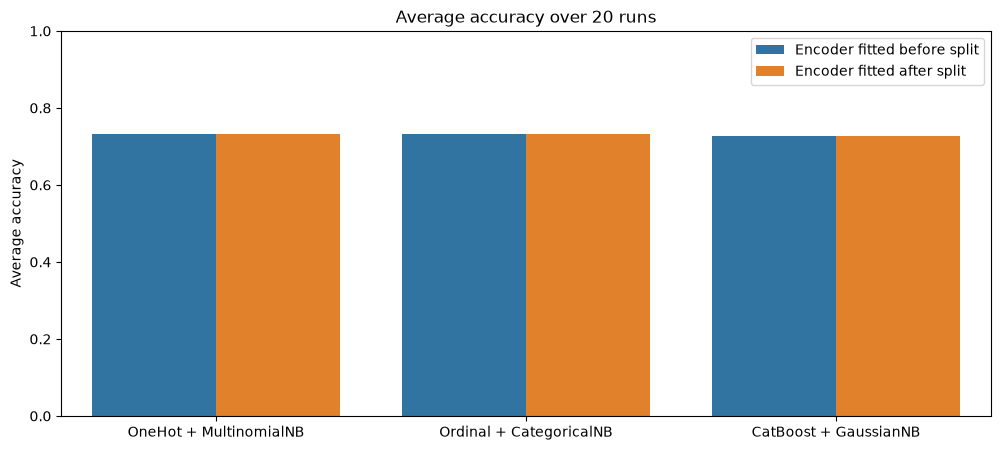

In [11]:
# plots
import seaborn as sns

names = ["OneHot + MultinomialNB", "Ordinal + CategoricalNB", "CatBoost + GaussianNB"]
avg_after_split = [statistics.mean(OH_scores), statistics.mean(OD_scores), statistics.mean(CB_scores)]
avg_before_split = [statistics.mean(OH_scores_before_split), statistics.mean(OD_scores_before_split), statistics.mean(CB_scores_before_split)]

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x=names * 2,
            y=avg_before_split + avg_after_split,
            hue=["Encoder fitted before split"] * 3 + ["Encoder fitted after split"] * 3,
            ax=ax)

ax.set_ylim(0, 1)
ax.set_ylabel("Average accuracy")
ax.set_title("Average accuracy over 20 runs")
plt.show()

### Task 5: Markdown Commentary